In [ ]:
# These examples use the Deepwave 0.1 interface and require PyTorch 2.4
# or later, as declared by Deepwave. Install plotting support too.
%pip install "deepwave>=0.1.0" matplotlib
# Recipe 2 also accepts the optional geomloss package; without it the
# script uses its differentiable inverse-CDF implementation.

# FWI recipes: exotic misfits, deep priors, and UQ on stock PyTorch

Competing differentiable-FWI packages advertise "batteries-included"
features: optimal-transport and soft-DTW misfits, deep-image-prior
reparameterisation, and dropout uncertainty quantification. This example
shows that each is a short recipe on top of Deepwave and the stock
PyTorch ecosystem -- composability rather than API surface.

Every recipe shares one small self-contained 2-D synthetic problem (a
constant background with a Gaussian slow anomaly), one cross-hole
transmission acquisition, and one forward-modelling setup. Two starting
models are used, both derived from that single problem:

* a *poor* start (a homogeneous model that is too fast, so the whole
  transmitted wavetrain is time-shifted) exposes cycle-skipping. It
  drives the optimal-transport recipe, where plain L2 fails and OT
  recovers.
* a *workable* start (the correct background, so only the anomaly is
  unknown) drives the soft-DTW, deep-image-prior, dropout-UQ, and
  TV-regularisation recipes, which are about ill-posedness and
  regularisation rather than cycle-skipping.

The script runs every recipe end-to-end, prints a metrics table (model
RMSE and data misfit per recipe), and writes one comparison figure.

``geomloss`` is an optional dependency used by the optimal-transport
recipe (``pip install geomloss``; it runs CPU-only with the tensorized
backend). If it is missing, the recipe falls back to the pure-torch
inverse-CDF Wasserstein misfit in ``cdf_wasserstein``.

By default this runs the full recipes used to produce the docs page.
Set the environment variable `DEEPWAVE_EXAMPLE_FAST=1` before running
the rest of the notebook to shrink every recipe's iteration count to a
quick (non-representative) smoke test -- useful for CI or for
confirming the notebook runs before committing to the full, slower
gallery.

In [2]:
"""FWI recipes: exotic misfits, deep priors, and UQ on stock PyTorch."""

import math
import os
import time

import matplotlib.pyplot as plt
import torch

import deepwave
from deepwave import scalar

try:
    from geomloss import SamplesLoss

    HAVE_GEOMLOSS = True
except ImportError:
    HAVE_GEOMLOSS = False

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ``DEEPWAVE_SMOKE=1`` shrinks this example so that it can be run quickly as
# an automated check; the default sizes are the ones the text describes.
smoke = os.environ.get("DEEPWAVE_SMOKE") == "1"

# Set DEEPWAVE_EXAMPLE_FAST=1 to shrink every recipe's iteration count to
# a quick (non-representative) smoke test, rather than the full runs used
# to produce the docs page. Useful for CI or for confirming this notebook
# runs before committing to the full, slower gallery.
# ``DEEPWAVE_SMOKE=1`` implies the same shrinkage.
_FAST = smoke or os.environ.get("DEEPWAVE_EXAMPLE_FAST", "0") not in (
    "0",
    "",
    "false",
    "False",
)


def _n_epochs(full, fast_min=5):
    """Scale an iteration count down in fast mode for quick smoke tests."""
    return max(fast_min, full // 10) if _FAST else full

## Shared problem

One true model (constant background + Gaussian slow anomaly), one
cross-hole transmission acquisition, one forward-modelling setup.

In [3]:
# Shrinking the grid also needs the anomaly's centre/width (in cells) and
# the acquisition to be rescaled by the same ratio, so the anomaly stays
# inside the domain and on the source-receiver transmission path.
ny, nx = (24, 40) if smoke else (60, 100)
dx = 10.0
dt = 0.002
freq = 15
nt = 160 if smoke else 400
peak_time = 1.5 / freq
anomaly_cy = ny // 2
anomaly_cx = nx // 2
anomaly_sy = 5 if smoke else 12
anomaly_sx = 6 if smoke else 16

y_grid = torch.arange(ny, device=device).float()
x_grid = torch.arange(nx, device=device).float()
yy, xx = torch.meshgrid(y_grid, x_grid, indexing="ij")
v_true = 1500.0 - 250.0 * torch.exp(
    -(
        ((yy - anomaly_cy) / anomaly_sy) ** 2
        + ((xx - anomaly_cx) / anomaly_sx) ** 2
    )
)

# Sources down the left edge, receivers down the right edge: the wave
# transmits through the anomaly, so its arrival time carries the signal.
n_shots = 4 if smoke else 8
source_locations = torch.zeros(
    n_shots, 1, 2, dtype=torch.long, device=device
)
source_locations[:, 0, 0] = torch.linspace(
    6, ny - 6, n_shots, device=device
).long()
source_locations[:, 0, 1] = 2
n_rec = 10 if smoke else 30
receiver_locations = torch.zeros(
    n_shots, n_rec, 2, dtype=torch.long, device=device
)
receiver_locations[..., 0] = (
    torch.linspace(2, ny - 2, n_rec, device=device)
    .long()
    .repeat(n_shots, 1)
)
receiver_locations[..., 1] = nx - 3
source_amplitudes = (
    deepwave.wavelets.ricker(freq, nt, dt, peak_time)
    .reshape(1, 1, -1)
    .repeat(n_shots, 1, 1)
    .to(device)
)

# Two starting models, both homogeneous.
v_start_workable = 1500.0 * torch.ones(ny, nx, device=device)  # correct bg
v_start_poor = 1600.0 * torch.ones(ny, nx, device=device)  # cycle-skips


def forward(v):
    """Model the receiver data for a velocity model ``v``."""
    return scalar(
        v,
        dx,
        dt,
        source_amplitudes=source_amplitudes,
        source_locations=source_locations,
        receiver_locations=receiver_locations,
        pml_freq=freq,
        max_vel=1700,
    ).receiver_amplitudes


observed_data = forward(v_true).detach()


def model_rmse(v):
    """Root-mean-square velocity error (m/s) against the true model."""
    return (((v - v_true) ** 2).mean() ** 0.5).item()


def data_misfit(v):
    """A common yardstick: L2 data MSE of a model, for the metrics table."""
    with torch.no_grad():
        return torch.nn.MSELoss()(forward(v), observed_data).item()


results = {}  # name -> (recovered_v, model_rmse, data_misfit)


def record(name, v):
    """Store a recovered model and print its metrics."""
    v = v.detach()
    results[name] = (v, model_rmse(v), data_misfit(v))
    print(
        f"  {name:18s} rmse={results[name][1]:7.2f}  "
        f"data={results[name][2]:.3e}",
        flush=True,
    )


def l2_loss(pred):
    """Scaled mean-squared-error data misfit."""
    return 1e3 * torch.nn.MSELoss()(pred, observed_data)


_DEFAULT_PIXEL_EPOCHS = _n_epochs(60)


def invert_pixels(loss_fn, v_start, n_epochs=_DEFAULT_PIXEL_EPOCHS, lr=6.0):
    """Plain pixel-space inversion driven by a data-misfit ``loss_fn``."""
    v = v_start.clone().requires_grad_()
    opt = torch.optim.Adam([v], lr=lr)
    for _ in range(n_epochs):
        opt.zero_grad()
        loss_fn(forward(v)).backward()
        opt.step()
    return v.detach()

## Recipe 1: L2 baseline

Baseline L2 FWI from the workable start (the reference the
regularisation recipes are judged against).

In [4]:
print("Recipe 1: L2 baseline (workable start)", flush=True)
t0 = time.time()
record("L2 baseline", invert_pixels(l2_loss, v_start_workable))
print(f"  ({time.time() - t0:.0f}s)", flush=True)

Recipe 1: L2 baseline (workable start)
  L2 baseline        rmse=  49.28  data=1.450e-03
  (39s)


## Recipe 2: optimal transport

Optimal-transport (Wasserstein) misfit -- a cycle-skipping demo.

W2 on raw signed seismograms is ill-defined: transport needs
non-negative mass. We map each trace to an energy density over time,
p(t) = a(t)^2 / sum_t a(t)^2. Squaring makes the mass non-negative and
emphasises energetic arrivals; normalising makes each trace a
probability measure, so predicted and observed mass match (balanced
OT). The ground cost is squared *time* distance, so a shifted arrival
costs ~ shift^2 -- a convex penalty far less prone to cycle-skipping
than L2 (Engquist & Froese 2014; Metivier et al. 2016). The price is
that squaring discards polarity: this is a phase-insensitive,
envelope-like comparison. We decimate the traces in time so the
Sinkhorn cost matrices stay small.

In [5]:
ot_time_factor = 4
ot_receiver_stride = 3
nt_ot = nt // ot_time_factor
ot_time_axis = (
    torch.arange(nt_ot, device=device).float() * dt * ot_time_factor
).reshape(1, nt_ot, 1)


def decimate(traces, factor):
    """Average-pool traces (..., nt) in time by an integer factor."""
    flat = traces.reshape(-1, 1, traces.shape[-1])
    return torch.nn.functional.avg_pool1d(flat, factor).reshape(
        *traces.shape[:-1], -1
    )


def energy_density(traces):
    """Map signed traces (B, nt) to non-negative densities over time."""
    energy = traces**2
    energy = energy + 1e-6 * energy.mean(dim=-1, keepdim=True)
    return energy / energy.sum(dim=-1, keepdim=True)


def _quantile(cdf, levels, t):
    """Differentiable inverse-CDF (quantile) via linear interpolation.

    ``torch.searchsorted`` only selects which pair of CDF samples brackets
    each level; that index choice is a discrete, non-differentiable
    decision (as with nearest-bin lookups generally) and does not need a
    gradient. The quantile *value* is then linearly interpolated between
    the bracketing ``(t, cdf)`` samples, so it is a differentiable function
    of ``cdf`` (and therefore of whatever produced it, e.g. ``pred``).
    """
    idx = torch.searchsorted(cdf, levels).clamp(1, cdf.shape[-1] - 1)
    cdf_hi = torch.gather(cdf, -1, idx)
    cdf_lo = torch.gather(cdf, -1, idx - 1)
    t_hi = t[idx]
    t_lo = t[idx - 1]
    frac = (levels - cdf_lo) / (cdf_hi - cdf_lo).clamp_min(1e-12)
    return t_lo + frac * (t_hi - t_lo)


def cdf_wasserstein(pred, target):
    """Pure-torch 1-D W2 via inverse-CDF (geomloss-free fallback).

    For 1-D distributions the squared Wasserstein-2 distance is the
    squared L2 distance between the quantile (inverse-CDF) functions
    (Metivier et al. 2016). We sample the quantile axis uniformly and read
    off the arrival *time* at each quantile of the energy density.

    The quantile lookup must be done with :func:`_quantile`, not plain
    ``t[torch.searchsorted(cdf, levels)]`` indexing: gathering ``t`` (a
    constant time axis) at the integer indices returned by
    ``torch.searchsorted`` (also non-differentiable) leaves the result with
    no path back to ``cdf`` at all, so ``pred``'s gradient is silently
    dropped and ``loss.backward()`` raises "does not require grad" instead
    of quietly producing a wrong (zero) gradient.
    """
    p = energy_density(decimate(pred, ot_time_factor).reshape(-1, nt_ot))
    q = energy_density(decimate(target, ot_time_factor).reshape(-1, nt_ot))
    cp = torch.cumsum(p, dim=-1)
    cq = torch.cumsum(q, dim=-1)
    levels = torch.linspace(0.0, 1.0, nt_ot, device=device).expand(
        cp.shape[0], -1
    )
    t = ot_time_axis.reshape(nt_ot)
    qp = _quantile(cp, levels, t)
    qq = _quantile(cq, levels, t)
    return ((qp - qq) ** 2).mean()


obs_ot = decimate(
    observed_data[:, ::ot_receiver_stride, :], ot_time_factor
).reshape(-1, nt_ot)

if HAVE_GEOMLOSS:
    print("Recipe 2: optimal transport (geomloss)", flush=True)
    _sinkhorn = SamplesLoss(
        "sinkhorn", p=2, blur=0.05, scaling=0.5, backend="tensorized"
    )
    obs_ot_density = energy_density(obs_ot)

    def ot_loss(pred):
        """Entropic-W2 misfit between per-trace energy densities."""
        p = energy_density(
            decimate(
                pred[:, ::ot_receiver_stride, :], ot_time_factor
            ).reshape(-1, nt_ot)
        )
        pos = ot_time_axis.repeat(p.shape[0], 1, 1)
        return _sinkhorn(p, pos, obs_ot_density, pos).sum()

else:
    print(
        "Recipe 2: geomloss missing -- pure-torch CDF Wasserstein fallback",
        flush=True,
    )

    def ot_loss(pred):
        """Pure-torch 1-D W2 fallback (see cdf_wasserstein)."""
        return 1e2 * cdf_wasserstein(pred, observed_data)


t0 = time.time()
# The same poor (too-fast) start cycle-skips L2 but not OT.
record("L2 (poor start)", invert_pixels(l2_loss, v_start_poor))
record("OT (poor start)", invert_pixels(ot_loss, v_start_poor))
print(f"  ({time.time() - t0:.0f}s)", flush=True)

Recipe 2: optimal transport (geomloss)
  L2 (poor start)    rmse= 223.42  data=1.126e-01
  OT (poor start)    rmse=  70.99  data=8.614e-02
  (102s)


## Recipe 3: soft-DTW misfit

A compact pure-torch soft-DTW (Cuturi & Blondel 2017): the classic
dynamic-time-warping recursion with the hard min replaced by a
log-sum-exp soft-min (temperature gamma), which makes it smooth and
differentiable. Like OT it is designed to tolerate time shifts, but it
keeps polarity. The DP is O(T^2) per trace pair, so we subsample the
traces in time and space and compare per-trace normalised waveforms.

In [6]:
def soft_dtw(x, y, gamma=0.1):
    """Soft-DTW discrepancy between batches of 1-D series (B, T).

    The classic DTW recursion with the hard ``min`` replaced by a
    log-sum-exp soft-min. We accumulate the cost matrix one row at a time
    into small per-cell tensors (rather than assigning into one big
    tensor in place), which keeps the autograd graph cheap to backprop.
    """
    n, t_len = x.shape
    dist = (x.unsqueeze(2) - y.unsqueeze(1)) ** 2  # (B, T, T)
    big = x.new_full((n,), 1e10)
    prev = [x.new_zeros(n)] + [big] * t_len  # previous row, j = 0..T
    for i in range(1, t_len + 1):
        curr = [big]  # j = 0 boundary is +inf
        for j in range(1, t_len + 1):
            neighbours = torch.stack([prev[j], curr[j - 1], prev[j - 1]])
            soft_min = -gamma * torch.logsumexp(-neighbours / gamma, dim=0)
            curr.append(dist[:, i - 1, j - 1] + soft_min)
        prev = curr
    return prev[t_len]


# soft-DTW resists time shifts where L2 does not: a Ricker shifted by +/-
# samples has an oscillating L2 misfit (larger shifts can score *better*
# than smaller ones -- cycle-skipping), whereas soft-DTW is a monotone
# bowl that grows with the shift. Two honesty caveats: raw soft-DTW is not
# a true metric -- soft-min is biased below the hard min, so the values
# carry a negative offset and D(x, x) != 0 (the non-negative "soft-DTW
# divergence" of Blondel et al. 2020 subtracts the self-terms); and the
# bowl is only clean at a fine enough sampling (coarse subsampling of a
# shifted wavelet reintroduces discretisation jumps).
_ref = deepwave.wavelets.ricker(freq, nt, dt, peak_time).reshape(1, -1)
print("soft-DTW vs L2 for a time-shifted wavelet:", flush=True)
print(f"  {'shift':>6s} {'L2':>10s} {'soft-DTW':>10s}", flush=True)
for shift in (-40, -20, -10, 0, 10, 20, 40):
    shifted = deepwave.wavelets.ricker(
        freq, nt, dt, peak_time + shift * dt
    ).reshape(1, -1)
    l2_val = ((shifted[:, :220] - _ref[:, :220]) ** 2).sum().item()
    dtw_val = soft_dtw(
        shifted[:, :220:2], _ref[:, :220:2], gamma=0.01
    ).item()
    print(f"  {shift:6d} {l2_val:10.4f} {dtw_val:10.4f}", flush=True)

sdtw_time_stride = 12
sdtw_receiver_stride = 6


def normalise_traces(traces):
    """Unit-normalise each trace so soft-DTW compares shape, not scale."""
    return traces / (traces.norm(dim=-1, keepdim=True) + 1e-9)


def subsample_sdtw(traces):
    """Subsample (shots, rec, nt) traces in space/time and flatten+norm."""
    sub = traces[:, ::sdtw_receiver_stride, ::sdtw_time_stride]
    return normalise_traces(sub.reshape(-1, sub.shape[-1]))


obs_sdtw = subsample_sdtw(observed_data)


def sdtw_loss(pred):
    """Soft-DTW misfit on subsampled, per-trace-normalised waveforms."""
    return 1e3 * soft_dtw(subsample_sdtw(pred), obs_sdtw).mean()


print("Recipe 3: soft-DTW (workable start)", flush=True)
t0 = time.time()
record(
    "soft-DTW",
    invert_pixels(
        sdtw_loss, v_start_workable, n_epochs=_n_epochs(40), lr=4.0
    ),
)
print(f"  ({time.time() - t0:.0f}s)", flush=True)

soft-DTW vs L2 for a time-shifted wavelet:
   shift         L2   soft-DTW
     -40    17.9737    -0.8713
     -20    26.3540    -1.5440
     -10    26.5170    -1.5857
       0     0.0000    -1.5946
      10    26.5170    -1.5868
      20    26.3540    -1.5679
      40    19.2943    -1.5060
Recipe 3: soft-DTW (workable start)
  soft-DTW           rmse=  76.22  data=1.872e-01
  (117s)


## Recipe 4: deep-image-prior reparameterisation

Instead of optimising velocity pixels, a small CNN maps a fixed random
latent to a velocity perturbation and we optimise the CNN weights
(Ulyanov et al. 2018; Wu & McMechan 2019 for FWI). The convolutional
structure biases the recovered model towards smooth, spatially-coherent
perturbations -- implicit regularisation with no explicit penalty term.

The output head is a plain linear convolution (the perturbation in m/s,
here scaled by 100), deliberately *not* wrapped in a bounded
nonlinearity: a saturating tanh output would give the optimiser a flat,
zero-gradient region to fall into and get stuck (a uniform, useless
model), which the extra gradient noise from the Recipe 5 dropout variant
reliably triggers. Gradient-norm clipping in ``invert_network`` adds a
second guard against a stray large step. We *clamp* the final velocity
to a physical band so that the noisy Monte-Carlo dropout passes in
Recipe 5 cannot wander to unstable/unphysical velocities -- clamp only
zeroes the gradient where a pixel is actually out of range (never
during normal training here), so it does not create the tanh trap.

In [7]:
V_MIN, V_MAX = 1000.0, 1700.0


class DeepImagePrior(torch.nn.Module):
    """Maps a fixed latent to a velocity perturbation via small convs."""

    def __init__(self, dropout=0.0):
        """Build the decoder (optionally with dropout for MC-UQ)."""
        super().__init__()
        self.register_buffer("latent", torch.randn(1, 8, ny // 4, nx // 4))
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(8, 16, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.Dropout2d(dropout),
            torch.nn.Upsample(scale_factor=2, mode="bilinear"),
            torch.nn.Conv2d(16, 16, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.Dropout2d(dropout),
            torch.nn.Upsample(scale_factor=2, mode="bilinear"),
            torch.nn.Conv2d(16, 1, 3, padding=1),
        )

    def forward(self):
        """Return a velocity model (background + CNN perturbation)."""
        perturbation = 100.0 * self.net(self.latent)[0, 0]
        return torch.clamp(v_start_workable + perturbation, V_MIN, V_MAX)


_DEFAULT_NETWORK_EPOCHS = _n_epochs(100)


def invert_network(model, n_epochs=_DEFAULT_NETWORK_EPOCHS, lr=5e-3):
    """Inversion with the velocity produced by a network (L2 misfit).

    Gradient-norm clipping keeps a stray large update from destabilising
    the network -- cheap insurance that matters most for the noisier
    dropout variant in Recipe 5.
    """
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(n_epochs):
        opt.zero_grad()
        l2_loss(forward(model())).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    return model


print("Recipe 4: deep image prior (workable start)", flush=True)
t0 = time.time()
dip = invert_network(DeepImagePrior().to(device))
record("DIP", dip().detach())
print(f"  ({time.time() - t0:.0f}s)", flush=True)

Recipe 4: deep image prior (workable start)
  DIP                rmse=  34.65  data=9.598e-04
  (48s)


## Recipe 5: dropout uncertainty (a heuristic UQ proxy)

Add dropout to the deep-image-prior CNN and keep it active at
inference: Monte-Carlo dropout (Gal & Ghahramani 2016) approximates a
Bayesian posterior, so the spread of many stochastic forward passes is
a cheap per-pixel uncertainty map. Treat it honestly as a proxy: it
reflects the prior/network's sensitivity, not the true posterior
curvature. For a physics-grounded alternative see the Hessian-based
uncertainty in :doc:`example_hessian` and Deepwave's scalar
Hessian-vector-product capability.

This uses the same architecture and optimiser as Recipe 4, adding only
dropout. The linear (non-saturating) output head and gradient clipping
(see Recipe 4) are what let it use that identical schedule without the
extra gradient noise from dropout destabilising the inversion.

In [8]:
print("Recipe 5: dropout uncertainty (workable start)", flush=True)
t0 = time.time()
dip_mc = invert_network(DeepImagePrior(dropout=0.1).to(device))
# Point estimate: the deterministic (dropout-off) prediction.
dip_mc.eval()
with torch.no_grad():
    dip_mc_point = dip_mc()
# Uncertainty: keep dropout active and take many stochastic passes.
dip_mc.train()
with torch.no_grad():
    samples = torch.stack(
        [dip_mc() for _ in range(_n_epochs(30, fast_min=5))]
    )
dip_mc_std = samples.std(0)
record("DIP+dropout", dip_mc_point)
print(f"  ({time.time() - t0:.0f}s)", flush=True)

Recipe 5: dropout uncertainty (workable start)
  DIP+dropout        rmse=  39.81  data=1.049e-02
  (49s)


## Recipe 6: TV / Tikhonov regularisation

Classic explicit penalty terms in a few lines of torch. Total variation
(sum of gradient magnitudes) favours piecewise-smooth models with sharp
edges; a Tikhonov penalty (squared gradient) would favour globally
smooth models. Add the penalty to the data misfit and let autograd
carry its gradient.

In [9]:
def total_variation(v):
    """Anisotropic total-variation penalty."""
    return (v[1:, :] - v[:-1, :]).abs().mean() + (
        v[:, 1:] - v[:, :-1]
    ).abs().mean()


def tikhonov(v):
    """Squared-gradient (Tikhonov) smoothness penalty (unused default)."""
    return ((v[1:, :] - v[:-1, :]) ** 2).mean() + (
        (v[:, 1:] - v[:, :-1]) ** 2
    ).mean()


def tv_loss(pred, v):
    """L2 data misfit plus a total-variation model penalty."""
    return l2_loss(pred) + 3.0 * total_variation(v)


print("Recipe 6: TV/Tikhonov (workable start)", flush=True)
t0 = time.time()
v_tv = v_start_workable.clone().requires_grad_()
opt = torch.optim.Adam([v_tv], lr=6.0)
for _ in range(_n_epochs(60)):
    opt.zero_grad()
    tv_loss(forward(v_tv), v_tv).backward()
    opt.step()
record("TV-regularised", v_tv.detach())
print(f"  ({time.time() - t0:.0f}s)", flush=True)

Recipe 6: TV/Tikhonov (workable start)
  TV-regularised     rmse=  39.29  data=9.413e-04
  (28s)


## Metrics table and comparison figure


Metrics (model RMSE in m/s, data = L2 data MSE):
  recipe              model RMSE   data misfit
  workable start           56.05     2.898e-01
  poor start              134.78     3.660e-01
  L2 baseline              49.28     1.450e-03
  L2 (poor start)         223.42     1.126e-01
  OT (poor start)          70.99     8.614e-02
  soft-DTW                 76.22     1.872e-01
  DIP                      34.65     9.598e-04
  DIP+dropout              39.81     1.049e-02
  TV-regularised           39.29     9.413e-04


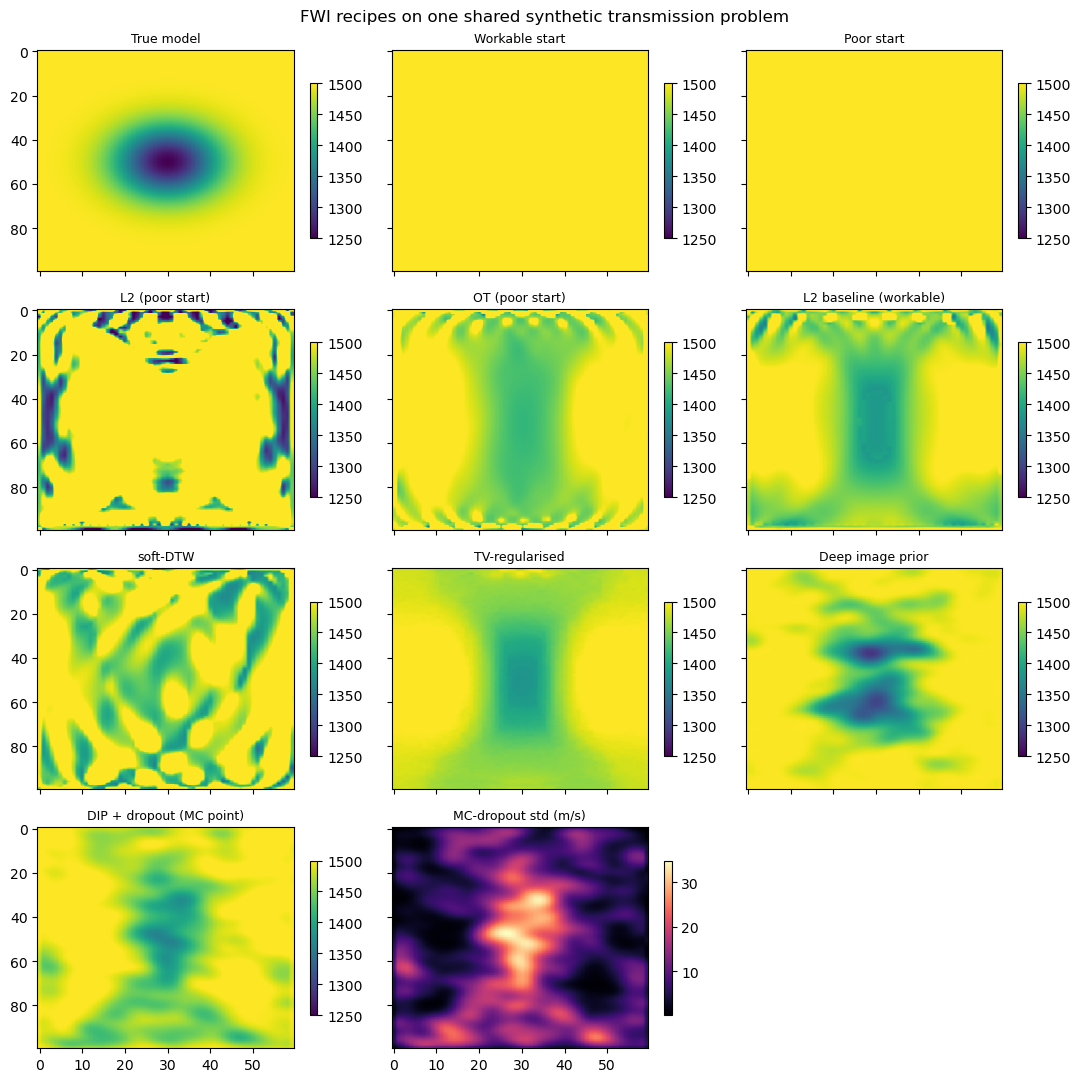


Saved example_fwi_recipes.jpg


In [10]:
print("\nMetrics (model RMSE in m/s, data = L2 data MSE):", flush=True)
print(f"  {'recipe':18s} {'model RMSE':>11s} {'data misfit':>13s}")
print(
    f"  {'workable start':18s} {model_rmse(v_start_workable):11.2f} "
    f"{data_misfit(v_start_workable):13.3e}"
)
print(
    f"  {'poor start':18s} {model_rmse(v_start_poor):11.2f} "
    f"{data_misfit(v_start_poor):13.3e}"
)
for name, (_, rmse, misfit) in results.items():
    print(f"  {name:18s} {rmse:11.2f} {misfit:13.3e}", flush=True)

vmin, vmax = float(v_true.min()), float(v_true.max())
fig, axes = plt.subplots(4, 3, figsize=(11, 11), sharex=True, sharey=True)
panels = [
    ("True model", v_true),
    ("Workable start", v_start_workable),
    ("Poor start", v_start_poor),
    ("L2 (poor start)", results["L2 (poor start)"][0]),
    ("OT (poor start)", results["OT (poor start)"][0]),
    ("L2 baseline (workable)", results["L2 baseline"][0]),
    ("soft-DTW", results["soft-DTW"][0]),
    ("TV-regularised", results["TV-regularised"][0]),
    ("Deep image prior", results["DIP"][0]),
    ("DIP + dropout (MC point)", results["DIP+dropout"][0]),
]
for ax, (title, model) in zip(axes.flat, panels):
    im = ax.imshow(
        model.cpu().T, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax
    )
    ax.set_title(title, fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.7)
# Penultimate panel: the Monte-Carlo dropout per-pixel uncertainty map.
ax = axes.flat[10]
im = ax.imshow(dip_mc_std.cpu().T, aspect="auto", cmap="magma")
ax.set_title("MC-dropout std (m/s)", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.7)
axes.flat[11].axis("off")
fig.suptitle("FWI recipes on one shared synthetic transmission problem")
plt.tight_layout()
plt.savefig("example_fwi_recipes.jpg", dpi=100)
plt.show()
print("\nSaved example_fwi_recipes.jpg", flush=True)

In [ ]:
assert all(
    math.isfinite(rmse) and math.isfinite(misfit)
    for _, rmse, misfit in results.values()
), "a recipe produced non-finite metrics"
assert results["L2 baseline"][1] < model_rmse(v_start_workable), (
    "L2 baseline did not improve on the workable starting model"
)